                                          Handwritten Digit Recognition using MNIST Dataset

## Project Objective
The objective of this project is to classify handwritten digit images (0–9) 
using machine learning and deep learning models.

## Dataset
We use the MNIST dataset which contains:
- 60,000 training images
- 10,000 testing images
- Each image is 28x28 grayscale
- 10 output classes (digits 0–9)

## Steps Involved
1. Load basic libraries
2. Load and understand the dataset
3. Perform basic data analysis
4. Visualize the images
5. Preprocess the data
6. Build and train models
7. Evaluate performance
8. Compare models
9. Observation & best model
10. Challenge faced
11. Conclusion

## Step 1 : Loading the basic Libraries
- We load the basic libraries that can we used in this file 

In [ ]:
!pip install tensorflow

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

ModuleNotFoundError: No module named 'tensorflow'

## Step 2 : Load The Dataset
- We load the MNIST dataset from TensorFlow Keras.
- The dataset is already split into training and testing sets.


Dataset split:
- Training set: 60,000 images
- Testing set: 10,000 images

In [ ]:
from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

## Step 3 : Basic Checks
We check:
- Number of samples
- Shape of images
- Unique classes
- Distribution of digits

In [ ]:
print(len(x_train))

60000


In [ ]:
print(len(x_test))

10000


In [ ]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [ ]:
print(x_train[0].shape)

(28, 28)


In [ ]:
print(x_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

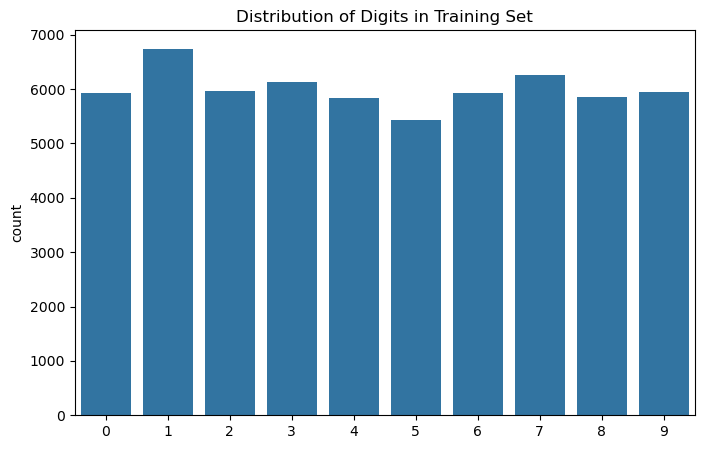

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x=y_train)
plt.title("Distribution of Digits in Training Set")
plt.show()

## Step 4 : Visualize Sample Images
- We display some images from the dataset to understand how handwritten digits look.

AxesImage(shape=(28, 28))


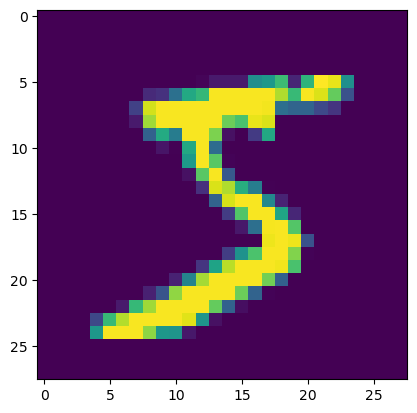

None


In [ ]:
print(plt.imshow(x_train[0]))
print(plt.show())

AxesImage(shape=(28, 28))


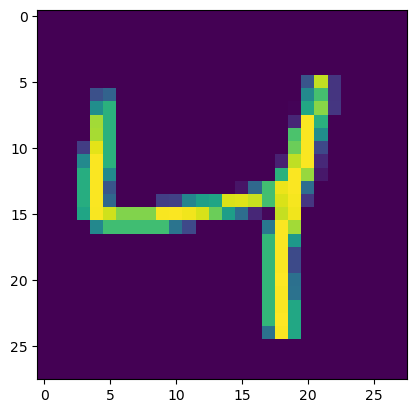

None


In [ ]:
print(plt.imshow(x_train[2]))
print(plt.show())

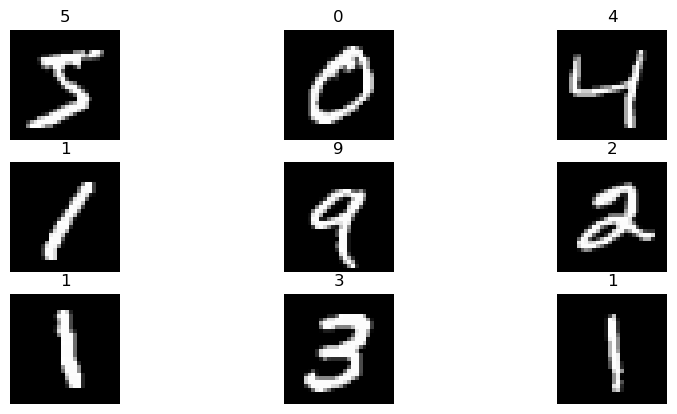

In [ ]:
## print first 9 images
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(6,3,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.show()

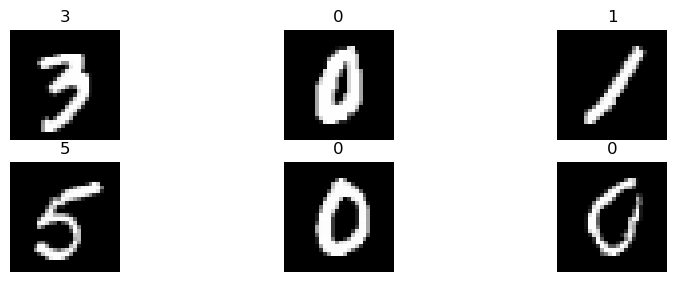

In [ ]:
# choose 6 random indices
rand_indices = np.random.choice(len(x_train), 6, replace=False)

# plot random images
plt.figure(figsize=(10,10))
for i, idx in enumerate(rand_indices):
    plt.subplot(6, 3, i+1)   # 2 rows, 3 columns
    plt.imshow(x_train[idx], cmap='gray')
    plt.title(y_train[idx])
    plt.axis('off')

plt.show()

### View an Image in More Detail

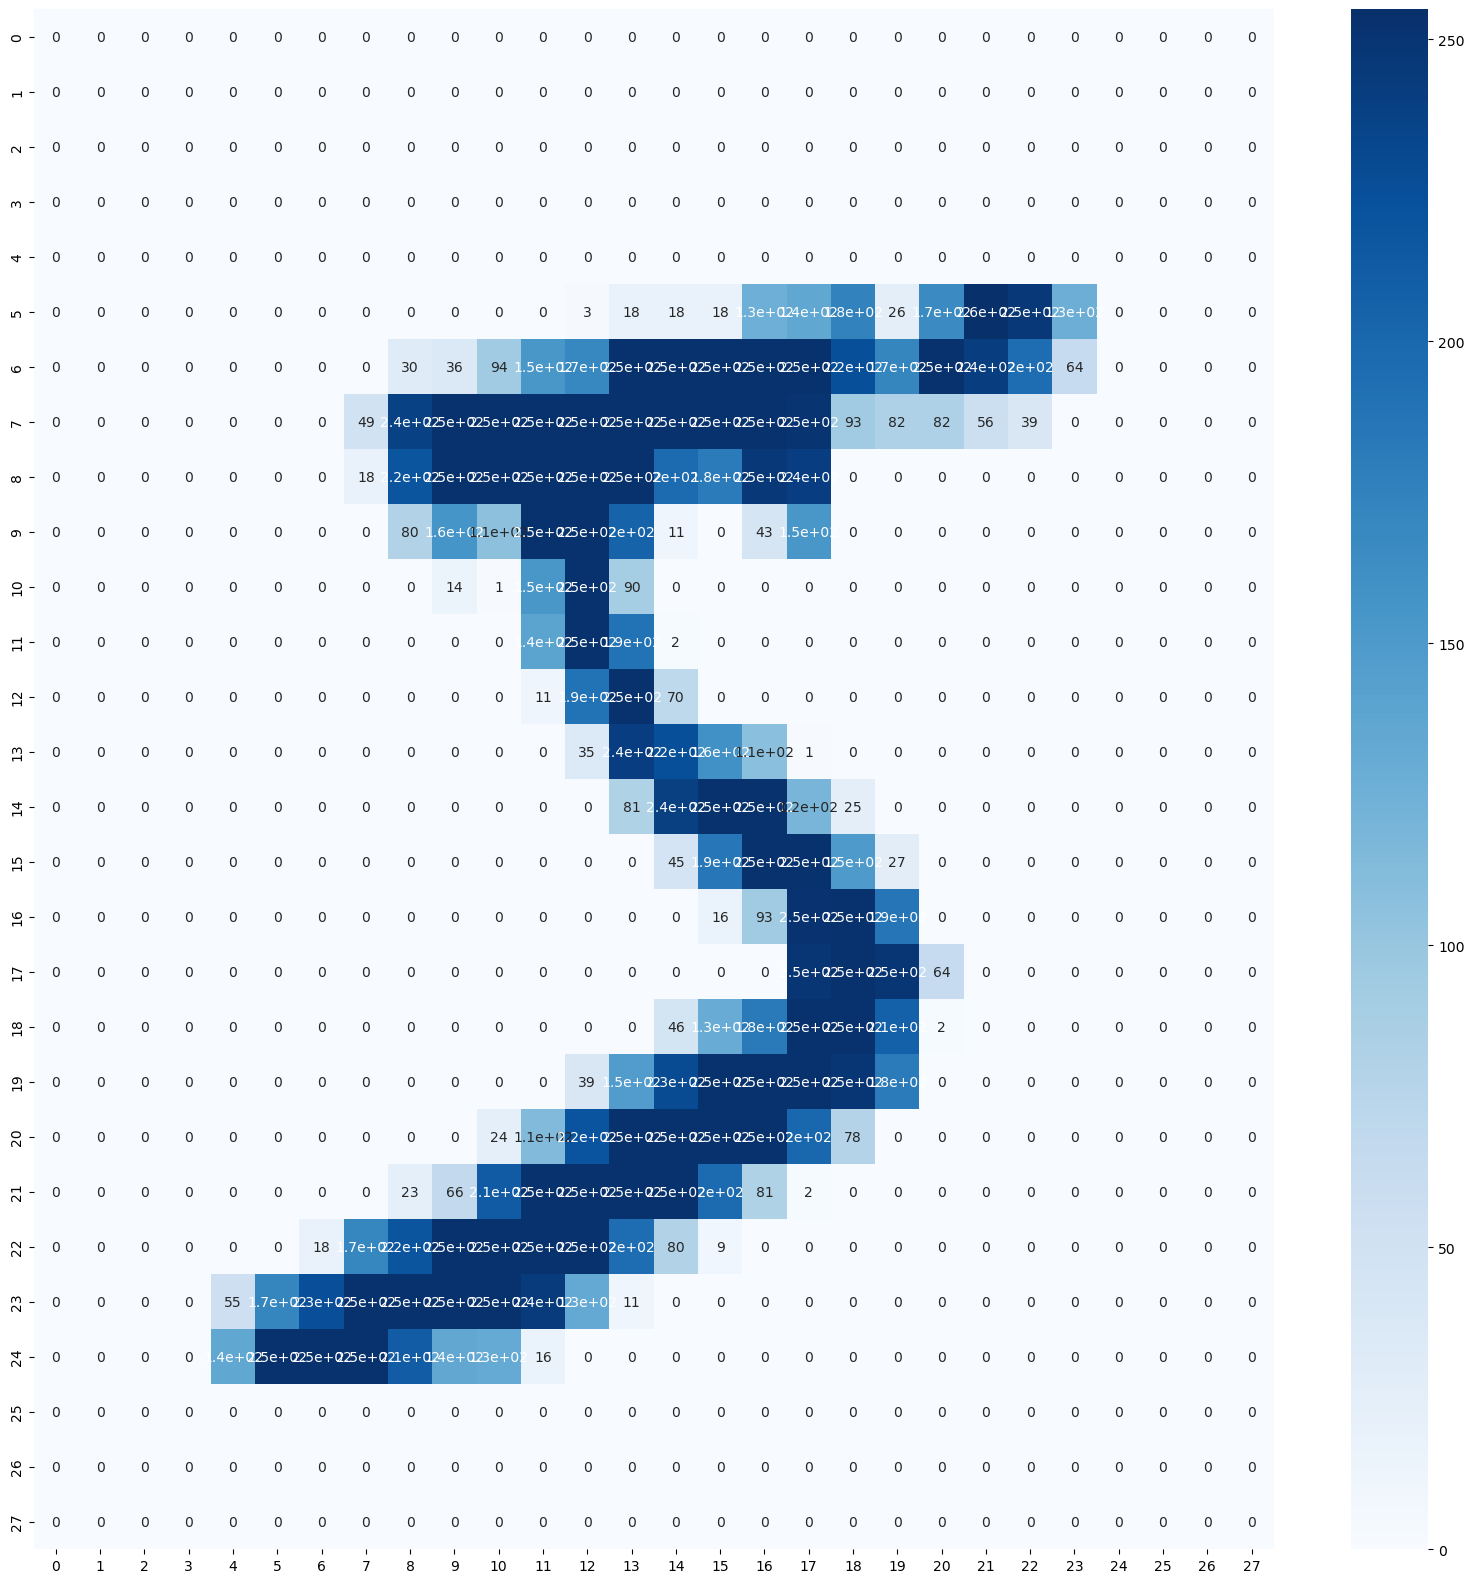

In [ ]:
plt.figure(figsize=(20,20))
sns.heatmap(x_train[0],cmap='Blues',annot=True)
plt.show()

In [ ]:
print(x_train.dtype)

uint8


## Step 5 : Data Preprocessing

We perform:
- Normalization (scale pixel values between 0 and 1)
- Reshaping for model compatibility
- One-hot encoding of labels

Before training the model, we perform preprocessing:

1. Normalize pixel values from 0–255 to 0–1
2. Convert labels into categorical format using one-hot encoding

In [ ]:
# rescale to have values within 0 - 1 range [0,255] --> [0,1]
x_train = x_train/255.0
x_test = x_test/255.0

print('X_train shape:', x_train.shape)
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')
print(x_train[0].shape, 'train samples')
print(x_test[0].shape, 'test samples')

X_train shape: (60000, 28, 28)
60000 train samples
10000 test samples
(28, 28) train samples
(28, 28) test samples


In [ ]:
print(x_train.min())
print(x_train.max())

0.0
1.0


In [ ]:
print(x_train[0].max())
print(x_train[0].min())
print(x_train[1].max())
print(x_train[1].min())
print(x_train[59999].max())
print(x_train[59999].min())

1.0
0.0
1.0
0.0
1.0
0.0


AxesImage(shape=(28, 28))


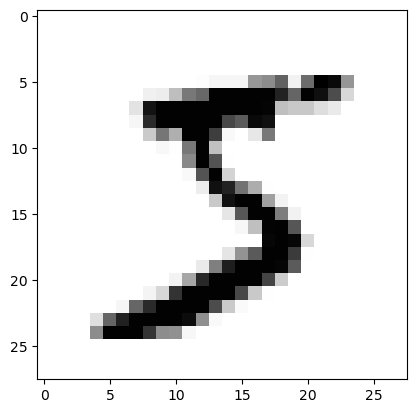

None


In [ ]:
print(plt.imshow(x_train[0],cmap='Grays'))
print(plt.show())

### View image after rescaling

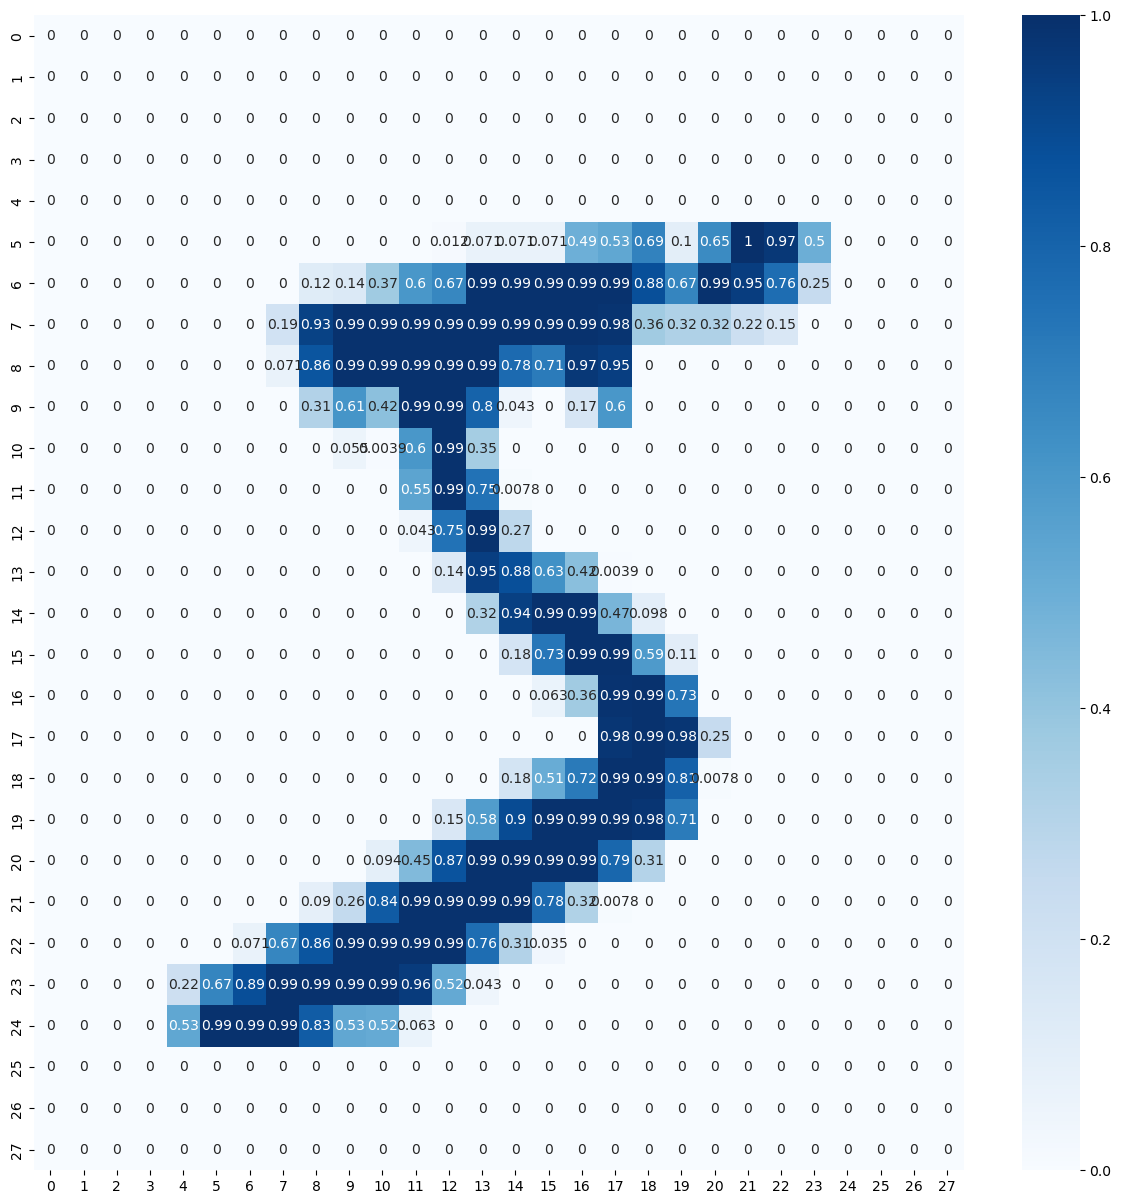

In [ ]:
plt.figure(figsize=(15,15))
sns.heatmap(x_train[0],cmap='Blues',annot=True)
plt.show()

### Reshape for Neural Network

In [ ]:
x_train_flat = x_train.reshape(len(x_train), 28*28)
x_test_flat = x_test.reshape(len(x_test), 28*28)

In [ ]:
print(x_train_flat.shape)
print(x_test_flat.shape)

(60000, 784)
(10000, 784)


In [ ]:
x_train_flat[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [ ]:
print(y_train.shape)
print(y_test.shape)

(60000,)
(10000,)


In [ ]:
print(y_train[2])

4


In [ ]:
print(y_train[:15])

[5 0 4 1 9 2 1 3 1 4 3 5 3 6 1]


In [ ]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

### One-Hot Encoding

In [ ]:
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

In [ ]:
print(y_train_cat.shape)
print(y_test_cat.shape)

(60000, 10)
(10000, 10)


In [ ]:
y_train_cat[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

In [ ]:
import pandas as pd
pd.DataFrame(y_train_cat,columns = range(0,10))

,0,1,2,3,4,5,6,7,8,9
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
59995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
59996,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
59997,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
59998,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## Step 6 : Model Building

## Logistic regreession

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

lr = LogisticRegression(max_iter=1000)
lr.fit(x_train_flat, y_train)

y_pred_lr = lr.predict(x_test_flat)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

Accuracy: 0.9258


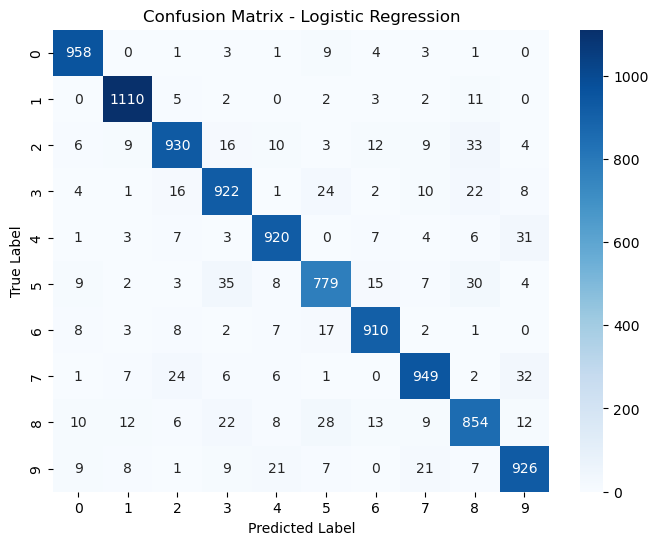

In [ ]:
# Create confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

The classification report provides more detailed metrics:

- Precision – How many predicted positives are actually correct
- Recall – How many actual positives were correctly identified
- F1-score – Balance between precision and recall
- Support – Number of actual samples in each class

In [ ]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       980
           1       0.96      0.98      0.97      1135
           2       0.93      0.90      0.91      1032
           3       0.90      0.91      0.91      1010
           4       0.94      0.94      0.94       982
           5       0.90      0.87      0.88       892
           6       0.94      0.95      0.95       958
           7       0.93      0.92      0.93      1028
           8       0.88      0.88      0.88       974
           9       0.91      0.92      0.91      1009

    accuracy                           0.93     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.93      0.93      0.93     10000



## KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train_flat, y_train)

y_pred_knn = knn.predict(x_test_flat)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 0.9705


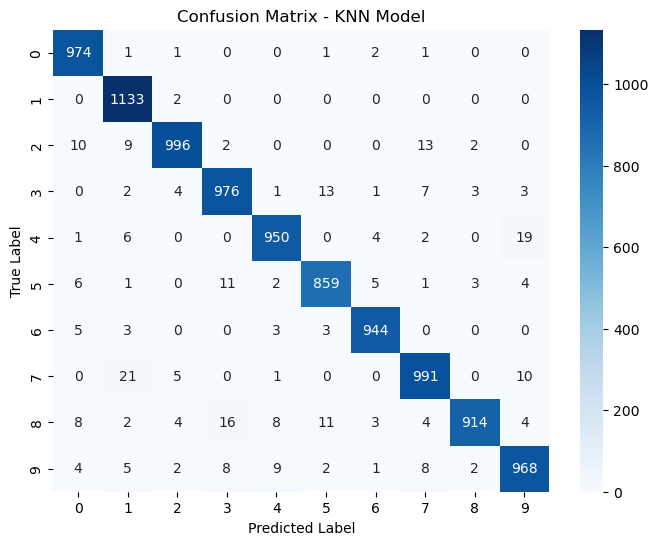

In [ ]:
# Create confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - KNN Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

The classification report provides more detailed metrics:

- Precision – How many predicted positives are actually correct
- Recall – How many actual positives were correctly identified
- F1-score – Balance between precision and recall
- Support – Number of actual samples in each class

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      1.00      0.98      1135
           2       0.98      0.97      0.97      1032
           3       0.96      0.97      0.96      1010
           4       0.98      0.97      0.97       982
           5       0.97      0.96      0.96       892
           6       0.98      0.99      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.99      0.94      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



## SVM

In [ ]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(x_train_flat, y_train)

y_pred_svm = svm.predict(x_test_flat)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

SVM Accuracy: 0.9792


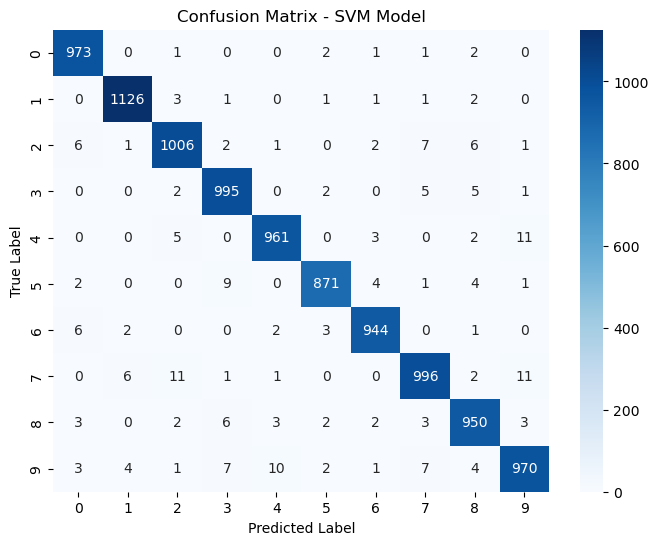

In [ ]:
# Create confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - SVM Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

The classification report provides more detailed metrics:

- Precision – How many predicted positives are actually correct
- Recall – How many actual positives were correctly identified
- F1-score – Balance between precision and recall
- Support – Number of actual samples in each class

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.97      0.99      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.99      0.98      0.98       892
           6       0.99      0.99      0.99       958
           7       0.98      0.97      0.97      1028
           8       0.97      0.98      0.97       974
           9       0.97      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



## ANN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model_ann = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Compile and train the model 

In [ ]:
# compile the model
model_ann.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

# train the model
model_ann.fit(x_train_flat, y_train_cat, epochs=10, batch_size=32)

# model evaluation
loss, acc = model_ann.evaluate(x_test_flat, y_test_cat)
print("ANN Accuracy:", acc)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9292 - loss: 0.2405
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9686 - loss: 0.1021
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9776 - loss: 0.0705
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9824 - loss: 0.0550
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9863 - loss: 0.0423
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9883 - loss: 0.0357
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9906 - loss: 0.0296
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9922 - loss: 0.0227
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9914 - loss: 0.0243
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9937 - loss: 0.0184
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9786 - loss: 0.0916        
ANN Accuracy: 0.978600025177002


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step  


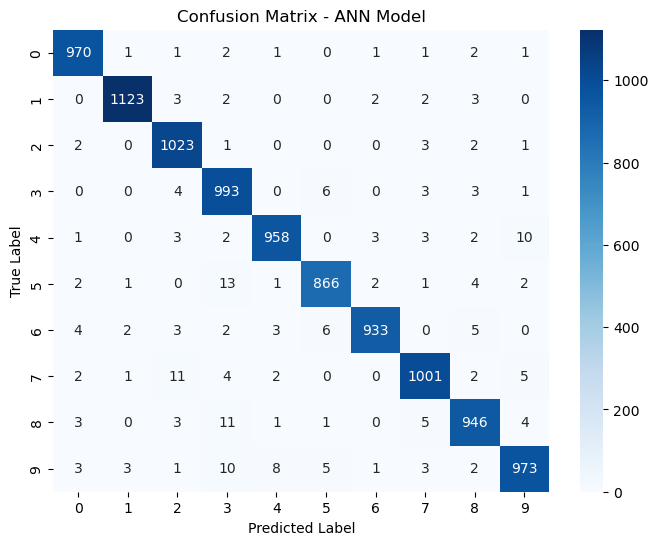

In [ ]:
# Predict probabilities for test data
y_pred_ann = model_ann.predict(x_test_flat)

# Convert probabilities to class labels
y_pred_ann_classes = np.argmax(y_pred_ann, axis=1)

# True labels
y_true = np.argmax(y_test_cat, axis=1)

# Create confusion matrix
cm_ann = confusion_matrix(y_true, y_pred_ann_classes)

# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm_ann, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - ANN Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

The classification report provides more detailed metrics:

- Precision – How many predicted positives are actually correct
- Recall – How many actual positives were correctly identified
- F1-score – Balance between precision and recall
- Support – Number of actual samples in each class

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred_ann_classes))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.99      0.98      1032
           3       0.95      0.98      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.97      0.98       892
           6       0.99      0.97      0.98       958
           7       0.98      0.97      0.98      1028
           8       0.97      0.97      0.97       974
           9       0.98      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



## CNN

### Reshape for CNN

In [ ]:
x_train_cnn = x_train.reshape(-1,28,28,1)
x_test_cnn = x_test.reshape(-1,28,28,1)

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten
model_cnn = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Compile and train the model

In [ ]:
# compile the model
model_cnn.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

# train the model
model_cnn.fit(x_train_cnn, y_train_cat, epochs=5, batch_size=32)

# model evaluation
loss, acc = model_cnn.evaluate(x_test_cnn, y_test_cat)
print("CNN Accuracy:", acc)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.9590 - loss: 0.1323
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.9863 - loss: 0.0440
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.9905 - loss: 0.0296
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.9927 - loss: 0.0216
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.9952 - loss: 0.0153
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9900 - loss: 0.0331
CNN Accuracy: 0.9900000095367432


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


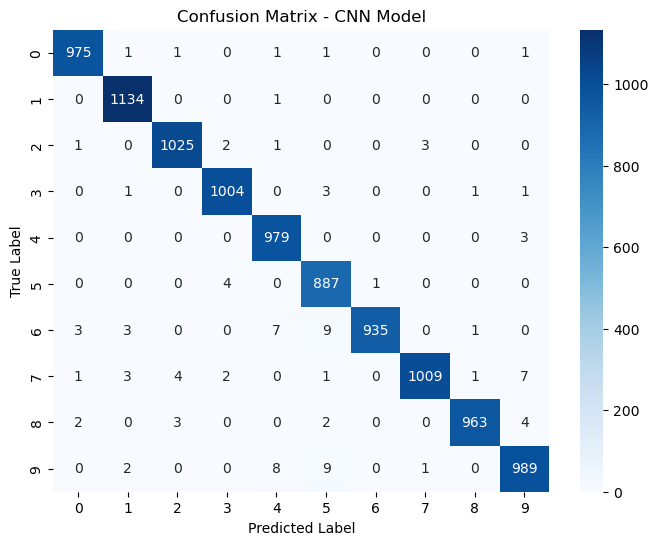

In [ ]:
# Predict probabilities
y_pred_cnn = model_cnn.predict(x_test_cnn)

# Convert probabilities to class labels
y_pred_cnn_classes = np.argmax(y_pred_cnn, axis=1)

# True labels
y_true = np.argmax(y_test_cat, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred_cnn_classes)

# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - CNN Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

The classification report provides more detailed metrics:

- Precision – How many predicted positives are actually correct
- Recall – How many actual positives were correctly identified
- F1-score – Balance between precision and recall
- Support – Number of actual samples in each class

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred_cnn_classes))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.98      1.00      0.99       982
           5       0.97      0.99      0.98       892
           6       1.00      0.98      0.99       958
           7       1.00      0.98      0.99      1028
           8       1.00      0.99      0.99       974
           9       0.98      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



## PREDICT A NEW IMG

In [ ]:
sample = x_test_cnn[5].reshape(1,28,28,1)
prediction = model_cnn.predict(sample)

print("Predicted Digit:", np.argmax(prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
Predicted Digit: 1


In [ ]:
sample = x_test_cnn[3].reshape(1,28,28,1)
prediction = model_cnn.predict(sample)

print("Predicted Digit:", np.argmax(prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Predicted Digit: 0


## Step 7 : Model Comparison Report

| Model               | Accuracy | Characteristics                                        |
| ------------------- | -------- | ------------------------------------------------------ |
| Logistic Regression |  92.58%  | Simple and fast but limited for complex image patterns |
| KNN                 |  97.05%  | Good accuracy but computationally expensive            |
| SVM                 |  97.92%  | High accuracy but slower training                      |
| ANN                 |  97.86%  | Learns nonlinear relationships better                  |
| CNN                 |  99.00%  | Best performance for image data                        |


## Step 8 : Observations

#### Logistic Regression
- Performs reasonably well.
- However, it cannot capture spatial relationships in image data.

#### KNN
- Achieves good accuracy.
- Prediction time is slower because it compares new samples with all training samples.

#### SVM
- Performs better than logistic regression.
- Computational cost increases with large datasets.

#### ANN
- Captures nonlinear patterns better.
- Provides strong classification performance.

#### CNN
- Best suited for image classification.
- Extracts spatial features using convolution layers.
- Achieves the highest accuracy.

### Best Model
The Convolutional Neural Network (CNN) is the best model for production deployment.

Reasons:
- Highest classification accuracy
- Automatically extracts image features
- Robust to variations in handwriting
- Designed specifically for image recognition tasks
- CNN models outperform traditional machine learning models because they preserve spatial relationships between pixels.

## Step 9 : Challenges Faced
1. High Dimensional Data = 
Each image contains 28 × 28 pixels (784 features) which increases computational complexity.

2. Image Data Handling = 
Machine learning models cannot directly process 2D image data.

3. Multi-Class Classification = 
The dataset contains 10 classes (digits 0–9).
One-Hot Encoding was applied to convert labels into categorical format.

4. Capturing Image Features = 
Flattening images removes spatial relationships between pixels.


## Step 10 : Conclusion
In this project, handwritten digit recognition was performed using the MNIST dataset. Several models including Logistic Regression, KNN, SVM, ANN, and CNN were trained and evaluated. The dataset was preprocessed through normalization and reshaping before model training. Model performance was evaluated using accuracy, confusion matrix, and classification report. Among all models, the CNN model achieved the highest accuracy because it can effectively capture spatial features from image data, making it the most suitable model for production.